In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import torch.optim as optim
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

## Data Loading

In [2]:
IMG_SIZE = 224
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [3]:
train_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Train', transform=train_transforms)
val_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Validation', transform=val_transforms)
test_dataset = datasets.ImageFolder(root='D:\Projects\Deepfake detection\datasets\images\Test', transform=val_transforms)

In [4]:
classes = train_dataset.classes

In [5]:
len(train_dataset), len(val_dataset), len(test_dataset)

(140002, 39428, 10905)

In [6]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [7]:
len(train_loader), len(val_loader), len(test_loader)

(4376, 1233, 341)

In [8]:
img, label = train_dataset[0]

In [9]:
img.shape

torch.Size([3, 224, 224])

In [10]:
label

0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0494049..2.64].


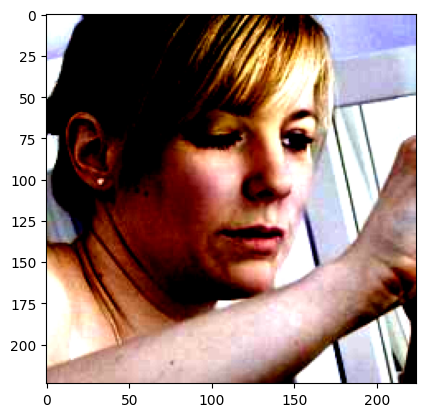

In [11]:
import matplotlib.pyplot as plt

plt.imshow(img.permute(1, 2, 0))

In [12]:
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Batch size:", train_loader.batch_size)

Training images: 140002
Validation images: 39428
Batch size: 32


## Model Building

In [13]:
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA Available: True
CUDA Version: 13.0
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [14]:
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

In [15]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [16]:
model.classifier[1] = nn.Linear(in_features=model.classifier[1].in_features, out_features=len(classes))

In [17]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [19]:
device

device(type='cuda')

In [20]:
print(next(model.parameters()).device)

cuda:0


In [25]:
for param in model.features.parameters():
    param.requires_grad = False

In [26]:
print(model.classifier[1].weight.requires_grad)
print(next(model.features.parameters()).requires_grad)

True
False


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [24]:
for epoch in range(5):
    current_loss = 0.0
    train_correct = 0
    model.train()
    model.features.eval()
    for i, (images, labels) in enumerate(train_loader):
        if i%100 == 0:
            print(f'Batch {i+1}/{len(train_loader)}')
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        predicted = torch.argmax(outputs, dim=1)
        loss.backward()
        optimizer.step()
        current_loss += loss.item()
        train_correct += (predicted == labels).sum().item()
    print(f'Epoch: {epoch+1}, Loss: {current_loss/len(train_loader)}, Accuracy: {100 * train_correct / len(train_loader.dataset)}%')

    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0
    with torch.no_grad():
        for i, (images, labels) in enumerate(val_loader):
            print(f'Validation Batch {i+1}/{len(val_loader)}')
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item()
            predicted = torch.argmax(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Validation Loss: {val_loss/len(val_loader)}, Accuracy: {100 * correct / total}%')

Batch 1/4376
Batch 101/4376
Batch 201/4376
Batch 301/4376
Batch 401/4376
Batch 501/4376
Batch 601/4376
Batch 701/4376
Batch 801/4376
Batch 901/4376
Batch 1001/4376
Batch 1101/4376
Batch 1201/4376
Batch 1301/4376
Batch 1401/4376
Batch 1501/4376
Batch 1601/4376
Batch 1701/4376
Batch 1801/4376
Batch 1901/4376
Batch 2001/4376
Batch 2101/4376
Batch 2201/4376
Batch 2301/4376
Batch 2401/4376
Batch 2501/4376
Batch 2601/4376
Batch 2701/4376
Batch 2801/4376
Batch 2901/4376
Batch 3001/4376
Batch 3101/4376
Batch 3201/4376
Batch 3301/4376
Batch 3401/4376
Batch 3501/4376
Batch 3601/4376
Batch 3701/4376
Batch 3801/4376
Batch 3901/4376
Batch 4001/4376
Batch 4101/4376
Batch 4201/4376
Batch 4301/4376
Epoch: 1, Loss: 0.8123666258218956, Accuracy: 49.87357323466808%
Validation Loss: 0.6932823509582154, Accuracy: 49.81485238916506%
Batch 1/4376
Batch 101/4376
Batch 201/4376
Batch 301/4376
Batch 401/4376
Batch 501/4376
Batch 601/4376
Batch 701/4376
Batch 801/4376
Batch 901/4376
Batch 1001/4376
Batch 1101/43

KeyboardInterrupt: 